# Deb Halder DX799 -Mod C1 Fall 2026 Dataset 2 (Web page Phishing Detection Dataset)... Week1 

https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset

### Web_page_dataset_phishing:

The dataset is available in https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset


This is a very good dataset and is highly usable for doing the phishing related EDA and we can build models to identify fraudulent /phishing websites based on the features provided

-The provided dataset includes 11430 URLs with 87 extracted features. The dataset is designed to be used as benchmarks for machine learning-based phishing detection systems. Features are from three different classes: 56 extracted from the structure and syntax of URLs, 24 extracted from the content of their correspondent pages, and 7 are extracted by querying external services. The dataset is balanced, it contains exactly 50% phishing and 50% legitimate URLs (information as available in Kaggle dataset page).

- This dataset has website and URL related data and this can work in conjunction with the email spam classification for phishing identification.  In the spam email we remove the URL parameters as it will cause noise. But we could indeitify URLs and then if there is an online data availabl;e which can be accessed which has URL related as given in this dataset it can provide us valuable information.

- Since this is all data about website  and ites domain there are no text body and thats the reason we will use the columns of data which are provided as features and do classification using SKLearn Linearmodel for regression


#### Web Page Phishing Detection Code Execution Flow

#### 1: Environment Setup & Data Ingestion
- **Import Libraries**: Load required libraries including `pandas`, `numpy`, `matplotlib`, `seaborn`, `kagglehub`, `shutil`, and `pathlib`.
- **Fetch Dataset**: Download the dataset `shashwatwork/web-page-phishing-detection-dataset` via `kagglehub`.
- **Load Data**: Read `dataset_phishing.csv` into a Pandas DataFrame for processing.

#### 2: Data Exploration & Validation
- **Dimension Inspection**: Check initial dataframe shape (11,430 rows and 89 columns).
- **Type & Summary Check**: Execute `df.info()` to verify data types and `df.describe()` to inspect statistical distributions.
- **Data Quality Checks**:
   * Scan for missing values (`df.isnull().sum()`).
   * Identify and quantify duplicate rows.
-. **Target Class Audit**: Verify class balance in the `status` column (5,715 legitimate vs. 5,715 phishing records).

#### 3: Data Preprocessing & Cleaning
- **Label Encoding**: Convert target string values in `status` into binary integers (`1` for phishing, `0` for legitimate).
- **Stratified Sampling**: Extract a balanced sample of 10,000 rows to maintain equal class representations.
- **Feature Dropping**:
   * Drop the `url` column due to high cardinality (11,429 unique values).
   * Identify and remove zero-variance (constant) columns across all samples.

#### 4: Exploratory Data Analysis (EDA)
- **Univariate Analysis**: Plot stacked histograms and Kernel Density Estimation (KDE) curves for features partitioned by target class.
- **Correlation Matrix**: Calculate feature correlations and isolate pairs with correlation coefficients $\vert{}r\vert{} \ge 0.5$.
- **Feature Distribution Visualization**: Generate box plots and violin plots for key features, such as domain age and Google indexing status.
- **Univariate and Bivariate analysis**
Graph and analysis of the features of datasetwhich will help us later

#### 5: Apply learning from week 3
- **forward selection**
- **backward selection**
- **PCA(pricipal component analysis)**
- **PCR (Principal component regression)**

---

### References
1. **Dataset**: Web Page Phishing Detection Dataset (`shashwatwork/web-page-phishing-detection-dataset`), Kaggle.

#### Observation from this notebook:

Lower RMSE indicates better predictive performance.
Lasso has the lowest median RMSE, approximately 0.262.
Elastic Net is very close, with a median around 0.262–0.263.
Ridge has the highest median RMSE, approximately 0.263.
The differences between the models are very small—roughly 0.001 RMSE or less.
The boxplots overlap considerably, indicating that the models have similar performance across the validation folds.
The validation error ranges are also similar, approximately 0.253–0.266.
There do not appear to be major outliers or large instability differences among the models.

#### Overall conclusion
Based only on the cross-validation plot at the end:

Lasso appears to be the best model by a small margin, followed closely by Elastic Net. Ridge is marginally worse. However, the differences are small and the overlapping distributions suggest that no model is clearly superior based on RMSE alone for this dataset.

We also notice that Lasso dropped 9 coefficeints to 0 (as the non coefficeints are reduced to 72 instead of Ridge which haqs retained all and its at 81. Elastic net is in between the Ridge and Lasso)

We also notice that amount of time needed to do the fit for the elastic net is lowest for ridge followed by lass and then elastic net is the most time taken. So we will watch this going forward . Here the dataset was pretty small with only 11400 approx rows with 82 filtered columns(out of 88) and small text values.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os


In [2]:
RANDOM_SEED = 42

### Let us import the data from kaggle and stage it in the local folder to process

In [3]:
from pathlib import Path
import shutil
import kagglehub

# Create the destination directory if it does not exist
destination_dir = Path("./dataset/phishing_website_dataset")
destination_dir.mkdir(parents=True, exist_ok=True)

# Download the latest Kaggle dataset
download_path = Path(
    kagglehub.dataset_download(
        "shashwatwork/web-page-phishing-detection-dataset"
    )
)

print("KaggleHub download directory:")
print(download_path)

# Find downloaded files
downloaded_files = [
    file_path
    for file_path in download_path.rglob("*")
    if file_path.is_file()
]

if not downloaded_files:
    raise FileNotFoundError(
        f"No files found in the Kaggle download directory: {download_path}"
    )

# Copy downloaded files into the project directory
for source_file in downloaded_files:
    destination_file = destination_dir / source_file.name
    shutil.copy2(source_file, destination_file)
    print(f"Saved: {destination_file}")

# Find the downloaded CSV file
csv_files = sorted(destination_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {destination_dir}"
    )

print("\nCSV files found:")
for csv_file in csv_files:
    print(csv_file.name)

# Load the first CSV file
website_csv = csv_files[0]
df_phishing_website_data = pd.read_csv(website_csv)

print("\nLoaded phishing website dataset:")
print(f"File: {website_csv}")
print(f"Shape: {df_phishing_website_data.shape}")

display(df_phishing_website_data.head())

# Delete only this dataset's KaggleHub cache directory
if download_path.exists() and download_path.is_dir():
    shutil.rmtree(download_path)
    print("\nDeleted KaggleHub cache directory:")
    print(download_path)
else:
    print("\nKaggleHub cache directory was not found:")
    print(download_path)

100%|██████████| 1.01M/1.01M [00:00<00:00, 7.95MB/s]

Extracting files...
KaggleHub download directory:
/Users/debasishhalder/.cache/kagglehub/datasets/shashwatwork/web-page-phishing-detection-dataset/versions/2
Saved: dataset/phishing_website_dataset/dataset_phishing.csv

CSV files found:
dataset_phishing.csv



Loaded phishing website dataset:
File: dataset/phishing_website_dataset/dataset_phishing.csv
Shape: (11430, 89)


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate



Deleted KaggleHub cache directory:
/Users/debasishhalder/.cache/kagglehub/datasets/shashwatwork/web-page-phishing-detection-dataset/versions/2


In [4]:
df_phishing_website_data.shape

(11430, 89)

In [5]:
df_phishing_website_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

#### Of the 88 columns we have two columns which are neither int or float ie status and url

In [6]:
df_phishing_website_data.describe()

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
count,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.0,11430.000000,...,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,1.143000e+04,11430.000000,11430.000000,11430.000000
mean,61.126684,21.090289,0.150569,2.480752,0.997550,0.022222,0.141207,0.162292,0.0,0.293176,...,0.124759,0.775853,0.439545,0.072878,492.532196,4062.543745,8.567566e+05,0.020122,0.533946,3.185739
std,55.297318,10.777171,0.357644,1.369686,2.087087,0.155500,0.364456,0.821337,0.0,0.998317,...,0.330460,0.417038,0.496353,0.259948,814.769415,3107.784600,1.995606e+06,0.140425,0.498868,2.536955
min,12.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,-1.000000,-12.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,33.000000,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,84.000000,972.250000,0.000000e+00,0.000000,0.000000,1.000000
50%,47.000000,19.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,242.000000,3993.000000,1.651000e+03,0.000000,1.000000,3.000000
75%,71.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,1.000000,0.000000,449.000000,7026.750000,3.738455e+05,0.000000,1.000000,5.000000
max,1641.000000,214.000000,1.000000,24.000000,43.000000,4.000000,3.000000,19.000000,0.0,19.000000,...,1.000000,1.000000,1.000000,1.000000,29829.000000,12874.000000,1.076799e+07,1.000000,1.000000,10.000000


In [7]:
#lets us check for null values
df_phishing_website_data.isnull().sum()

url                0
length_url         0
length_hostname    0
ip                 0
nb_dots            0
                  ..
web_traffic        0
dns_record         0
google_index       0
page_rank          0
status             0
Length: 89, dtype: int64

In [8]:
# let us check if there are any rows with null values
df_phishing_website_data[df_phishing_website_data.isnull().any(axis=1)]


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status


#### There are no rows with null values

In [9]:
#check if there are duplicate rows
df_phishing_website_data.duplicated().sum()

0

#### There are no duplicate rows

In [10]:
#lets check how many unique values are there in status
df_phishing_website_data['status'].nunique()



2

In [11]:
df_phishing_website_data['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

### The dataset is balanced dataset with equal number of legitimate and phishing site information

In [12]:
#let us change the dtype of status to int where 0 is 'legitimate' and 1 is 'phishing'
df_phishing_website_data['status'] = df_phishing_website_data['status'].apply(lambda x: 1 if x.split()[0] == 'phishing' else 0)
df_phishing_website_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [13]:
#lets check count of unique values in url
df_phishing_website_data['url'].unique().shape

(11429,)

In [14]:
# Create a random sample of 1000 rows while maintaining class balance
def create_balanced_sample(df, sample_size=500, random_state=42):
    # calculate the number of samples needed from each class
    samples_per_class = sample_size // 2

    # split the data by class
    spam = df[df['status'] == 1]
    non_spam = df[df['status'] == 0]

    # sample equally from each class
    spam_sample = spam.sample(n=samples_per_class, random_state=random_state)
    non_spam_sample = non_spam.sample(n=samples_per_class, random_state=random_state)

    # combine the samples
    balanced_sample = pd.concat([spam_sample, non_spam_sample])

    # chuffle the combined sample
    balanced_sample = balanced_sample.sample(frac=1, random_state=random_state).reset_index(drop=True)

    return balanced_sample

# create the balanced sample
sampled_df = create_balanced_sample(df_phishing_website_data, sample_size= 10000, random_state=39)

# verify the sample
print("Original dataset shape:", df_phishing_website_data.shape)
print("Sampled dataset shape:", sampled_df.shape)
print("\nClass distribution in sample:")
print(sampled_df['status'].value_counts())



Original dataset shape: (11430, 89)
Sampled dataset shape: (10000, 89)

Class distribution in sample:
status
0    5000
1    5000
Name: count, dtype: int64


### we will not use the URL info as it looks to be unique URL and we see total 11429 unique urls


In [15]:
# lets take the sampled df and drop the url column
sampled_df=sampled_df.drop(columns=['url'])

In [16]:
def perform_univariate_analysis(df, n_cols=4, plot_size=3):
    """
    Plot univariate distributions for numeric predictors by phishing status.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset containing numeric features and a 'status' column.
    n_cols : int, default=4
        Number of plots per row.
    plot_size : int or float, default=3
        Size of each subplot.
    """

    print("Performing Univariate Analysis...")

    numeric_features = [
        column
        for column in df.select_dtypes(include="number").columns
        if column != "status"
    ]

    if not numeric_features:
        raise ValueError(
            "No numeric predictor features were found in the dataframe."
        )

    n_rows = (
        len(numeric_features) + n_cols - 1
    ) // n_cols

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(
            n_cols * plot_size,
            n_rows * plot_size
        ),
        squeeze=False,
        constrained_layout=True
    )

    axes = axes.ravel()

    for idx, feature in enumerate(numeric_features):
        sns.histplot(
            data=df,
            x=feature,
            hue="status",
            multiple="stack",
            kde=False,
            ax=axes[idx]
        )

        axes[idx].set_title(
            f"Distribution of {feature}",
            fontsize=9
        )

        axes[idx].tick_params(
            axis="both",
            labelsize=7
        )

    for ax in axes[len(numeric_features):]:
        fig.delaxes(ax)

    plt.show()

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

def perform_bivariate_analysis(
    df,
    n_cols=4,
    plot_size=3,
    heatmap_size=12,
    annotate_corr=True
):
    if "status" not in df.columns:
        raise ValueError("The dataframe must contain a 'status' column.")

    numeric_df = df.select_dtypes(include="number")
    features = [col for col in numeric_df.columns if col != "status"]

    if not features:
        print("No numeric features to plot.")
        return

    # Correlation matrix
    correlation_matrix = numeric_df.corr()

    fig, ax = plt.subplots(
        figsize=(heatmap_size, heatmap_size),
        constrained_layout=True
    )

    sns.heatmap(
        correlation_matrix,
        annot=annotate_corr,
        annot_kws={"fontsize": 7},
        cmap="magma",
        center=0,
        fmt=".2f",
        square=True,
        ax=ax
    )

    ax.set_title("Correlation Matrix of Features", fontsize=12)
    ax.tick_params(axis="x", labelsize=7, rotation=90)
    ax.tick_params(axis="y", labelsize=7, rotation=0)
    plt.show()

    significant_correlations = create_correlation_df(
        correlation_matrix,
        threshold=0.5
    )
    print("Significant Correlation values:\n", significant_correlations)

    # Shared layout for violin and box plots
    n_cols = min(n_cols, len(features))
    n_rows = (len(features) + n_cols - 1) // n_cols

    for title, plot_function in [
        ("Violin Plots by Status", sns.violinplot),
        ("Box Plots by Status", sns.boxplot)
    ]:
        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(n_cols * plot_size, n_rows * plot_size),
            squeeze=False,
            constrained_layout=True
        )

        fig.suptitle(title, fontsize=14)
        axes = axes.ravel()

        for idx, feature in enumerate(features):
            ax = axes[idx]

            plot_function(
                data=df,
                x="status",
                y=feature,
                ax=ax
            )

            ax.set_box_aspect(1)  # Square plotting area
            ax.set_title(f"{feature} by Status", fontsize=9)
            ax.set_xlabel("Status", fontsize=8)
            ax.set_ylabel(feature, fontsize=8)
            ax.tick_params(axis="both", labelsize=7)

        # Remove unused subplots
        for ax in axes[len(features):]:
            fig.delaxes(ax)

        plt.show()

In [18]:
# Four square plots per row
#perform_bivariate_analysis(df_phishing_web_cleaned, n_cols=4, plot_size=3)

In [19]:
FONT_SIZE = 9

def perform_kde_analysis(df, n_cols=4, plot_size=3):
    features = [col for col in df.columns if col != 'status']
    n_rows = (len(features) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * plot_size, n_rows * plot_size),
        squeeze=False
    )
    fig.suptitle('KDE Plots by Feature', fontsize=FONT_SIZE, y=1.02)
    axes = axes.flatten()

    for idx, feature in enumerate(features):
        sns.kdeplot(
            data=df, x=feature, hue='status',
            ax=axes[idx], warn_singular=False
        )
        axes[idx].set_title(f'KDE Plot of {feature}', fontsize=FONT_SIZE)
        axes[idx].set_box_aspect(1)

    for idx in range(len(features), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    plt.show()

In [20]:
#perform_kde_analysis(df_phishing_web_cleaned, n_cols=4, plot_size=3)

In [21]:
def analyze_phishing_data(df, n_cols=4, plot_size=3):
	#execute it in the below sequence
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df, n_cols=4, plot_size=3)
	print("\nPerforming Bivariate Analysis...")
	perform_bivariate_analysis(df, n_cols=4, plot_size=3)
	print("\nPerforming KDE Analysis...")
	perform_kde_analysis(df, n_cols=4, plot_size=3)

In [22]:
def analyze_phishing_web_Univariate_data(df, n_cols=4, plot_size=3):
	print("Performing Univariate Analysis...")
	perform_univariate_analysis(df, n_cols=4, plot_size=3)


In [23]:
def analyze_phishing_web_Bivariate_data(df, n_cols=4, plot_size=3):
	print("\nPerforming Bivariate Analysis...")
	perform_bivariate_analysis(df, n_cols=4, plot_size=3)
	print("\nPerforming KDE Analysis...")
	perform_kde_analysis(df, n_cols=4, plot_size=3)

In [24]:
def create_correlation_df(correlation_matrix, threshold=0.5):

    #  creates a DataFrame of significant correlations.

    correlations = []

    for i in range(len(correlation_matrix.columns)):
        for j in range(i + 1, len(correlation_matrix.columns)):
            corr_value = correlation_matrix.iloc[i, j]
            if abs(corr_value) >= threshold:
                correlations.append({
                    'Feature 1': correlation_matrix.columns[i],
                    'Feature 2': correlation_matrix.columns[j],
                    'Correlation': corr_value
                })

    corr_df = pd.DataFrame(correlations)
    return corr_df.sort_values('Correlation', key=abs, ascending=False)


In [25]:
# Remove columns which has same values barring the first one(retain the first column drop the copies)
def keep_one_constant_column(df):
    is_constant = (df == df.iloc[0]).all()
    constant_cols = is_constant[is_constant].index

    # Keep all non-constant columns + the first constant column
    cols_to_drop = constant_cols[1:]
    return df.drop(columns=cols_to_drop)

In [26]:
df_phishing_web_cleaned = keep_one_constant_column(sampled_df)

### Lets do some preliminary univariate analysis which may show us some interesting facts abou the URL's for phishing:

- We will not do Bivariate analysis as we have good understanding about the data through code is there in this notebook as its part of my standard template
- Domain age is shorter
- Google index are mostly zero (i.e non indexed and thereare few more)

Performing Univariate Analysis...


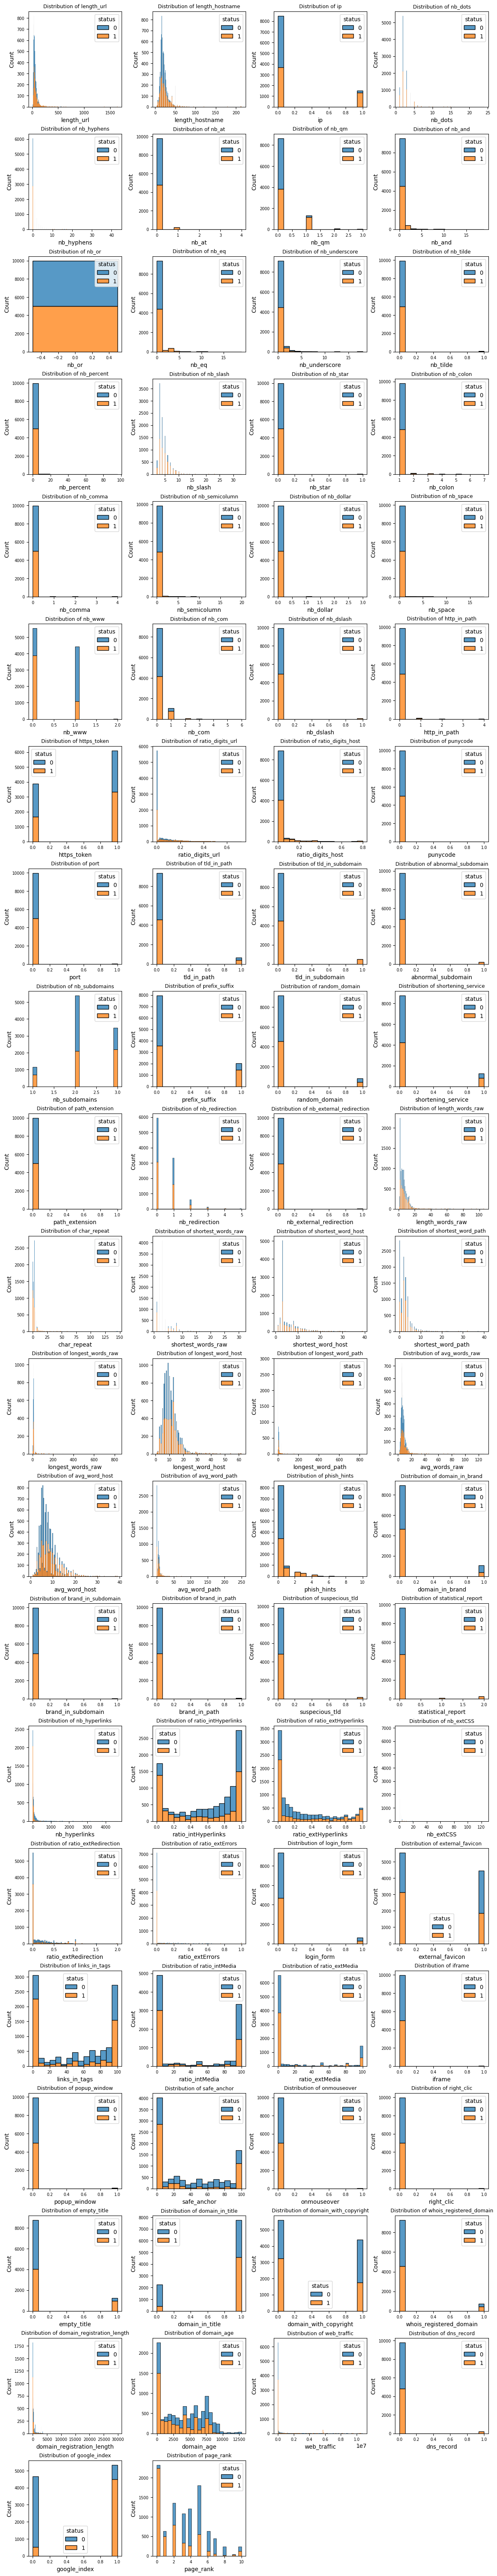

In [27]:
#print("Performing Univariate Analysis...")
perform_univariate_analysis(
    df_phishing_web_cleaned,
    n_cols=4,
    plot_size=3
)

### Key Observation from Univariate Analysis 

The plots show that phishing cases (status 1) tend to have lower website page ranks and lower recorded domain ages than legitimate cases (status 0). Phishing URLs also appear less likely to contain “www.” The Google-index indicator shows a particularly clear difference between the two groups, suggesting that it could help identify phishing.

These website and URL characteristics are promising indicators for classification, but none proves that an individual case is phishing. Before interpreting domain age, we should confirm that zero means a newly registered domain rather than missing information.


Performing Bivariate Analysis...


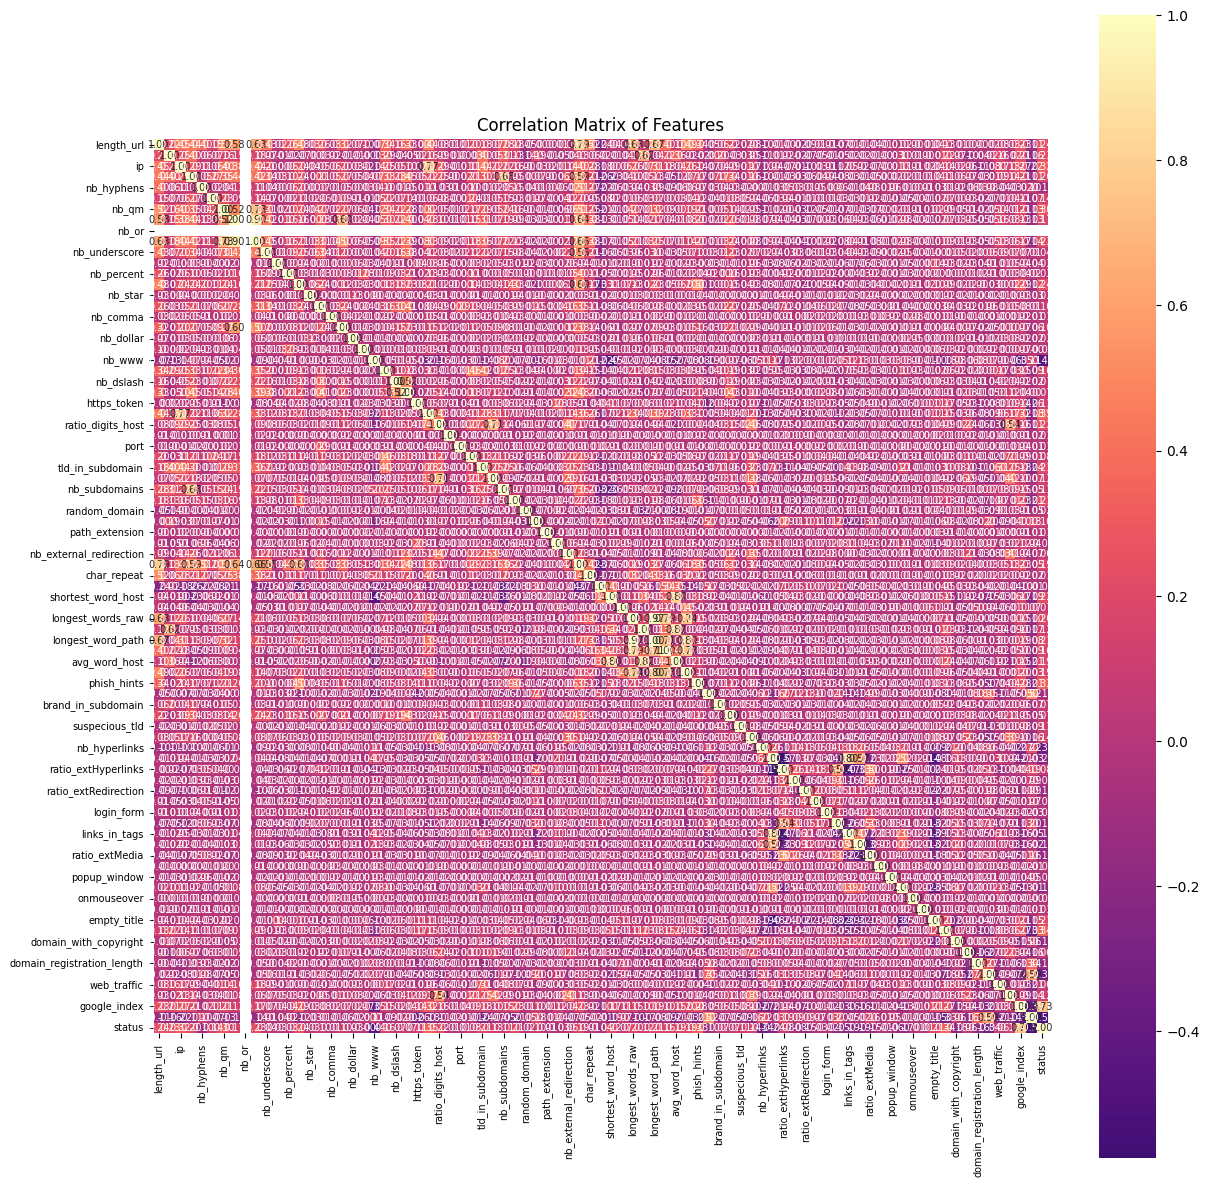

Significant Correlation values:
               Feature 1            Feature 2  Correlation
27    longest_words_raw    longest_word_path     0.968710
15               nb_and                nb_eq     0.904700
30    longest_word_host        avg_word_host     0.816041
32    longest_word_path        avg_word_path     0.799737
36  ratio_intHyperlinks        links_in_tags     0.799399
26   shortest_word_host        avg_word_host     0.798854
28    longest_words_raw        avg_words_raw     0.793276
3            length_url     length_words_raw     0.793031
8                    ip     ratio_digits_url     0.766773
29    longest_words_raw        avg_word_path     0.736015
33        avg_words_raw        avg_word_path     0.734789
41         google_index               status     0.730511
13                nb_qm                nb_eq     0.728555
31    longest_word_path        avg_words_raw     0.710211
24    ratio_digits_host   abnormal_subdomain     0.708225
9               nb_dots        nb_subdo

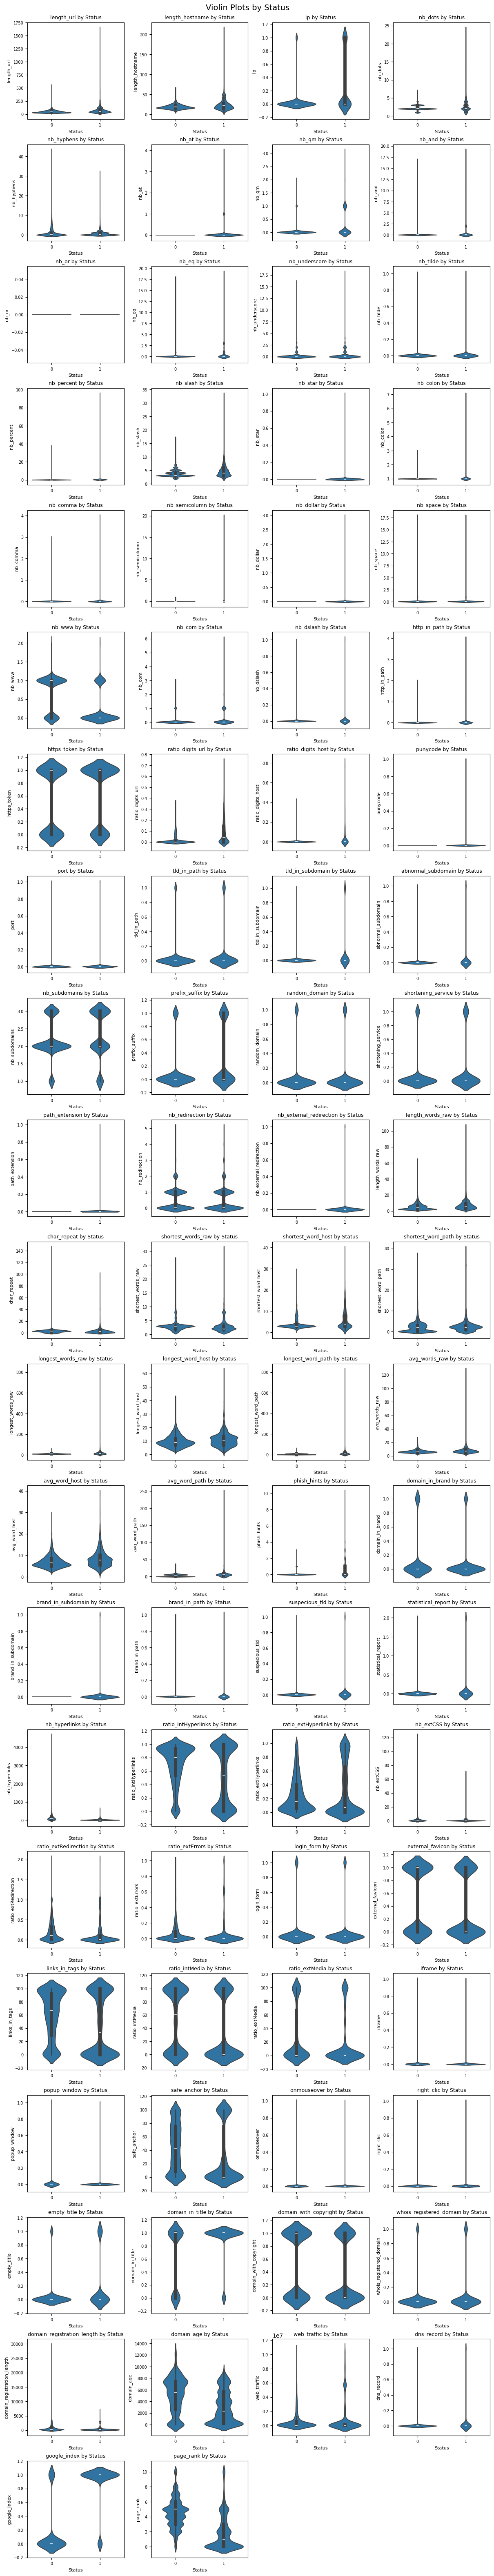

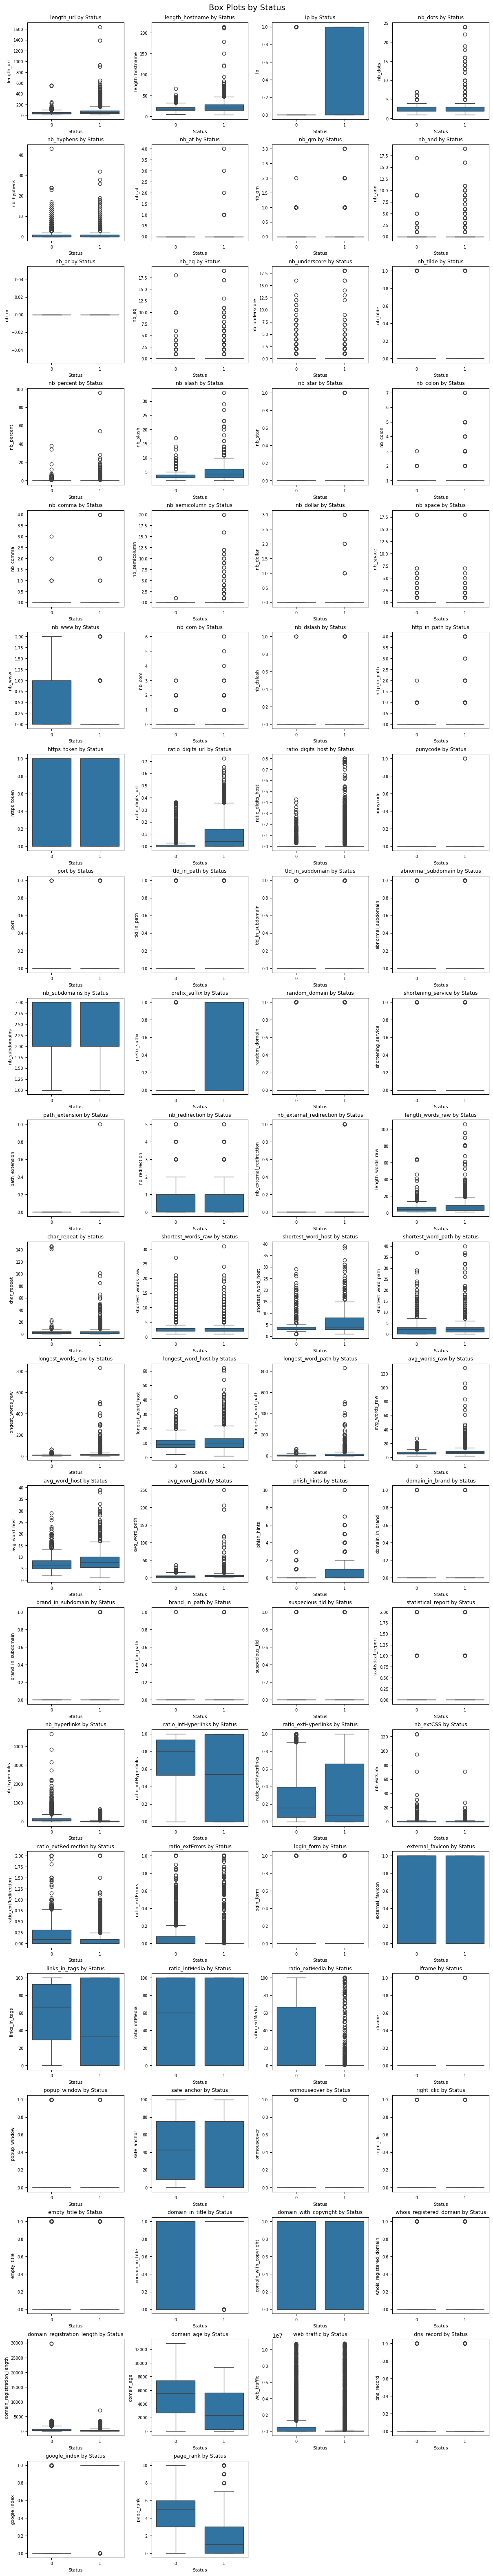

In [28]:
#Perform Bivariate analysis 
print("\nPerforming Bivariate Analysis...")
perform_bivariate_analysis(df_phishing_web_cleaned, n_cols=4, plot_size=3)


### Observations from Bivariate Analysis

**1. Correlation results**

The Google-index indicator has the strongest listed correlation with phishing status, at approximately **0.73**. Higher values of this indicator are associated with phishing, although its coding must be checked before interpreting this as being indexed or not indexed by Google.

Page rank has a correlation of approximately **−0.51** with phishing status, supporting the observation that phishing cases tend to have lower page ranks.

Some predictors are strongly related to each other. For example, the longest word length in the URL and the longest word length in its path have a correlation of approximately **0.97**. The counts of “&” and “=” characters have a correlation of approximately **0.90**. These pairs may provide overlapping information and should be considered when assessing multicollinearity.


**2. Box plots**

The phishing group (status 1) has a lower median page rank and lower median recorded domain age than the legitimate group (status 0). These differences suggest that page rank and domain age could help distinguish the groups.

Many features, including URL length, number of hyperlinks, and web traffic, contain values far beyond their usual range. These observations deserve investigation, but they should not automatically be treated as errors or removed.

**3. Violin plots**

Phishing cases are concentrated around low page ranks and low recorded domain ages, while legitimate cases are more concentrated at higher values. However, the distributions overlap, so neither feature can perfectly separate phishing from legitimate cases.

The Google-index indicator shows particularly clear separation: phishing cases concentrate at 1, while legitimate cases concentrate at 0. Phishing URLs also concentrate more at zero occurrences of “www,” whereas legitimate URLs concentrate more at one occurrence.

Many other features cluster near zero in both groups, showing less obvious separation.



Performing KDE Analysis...


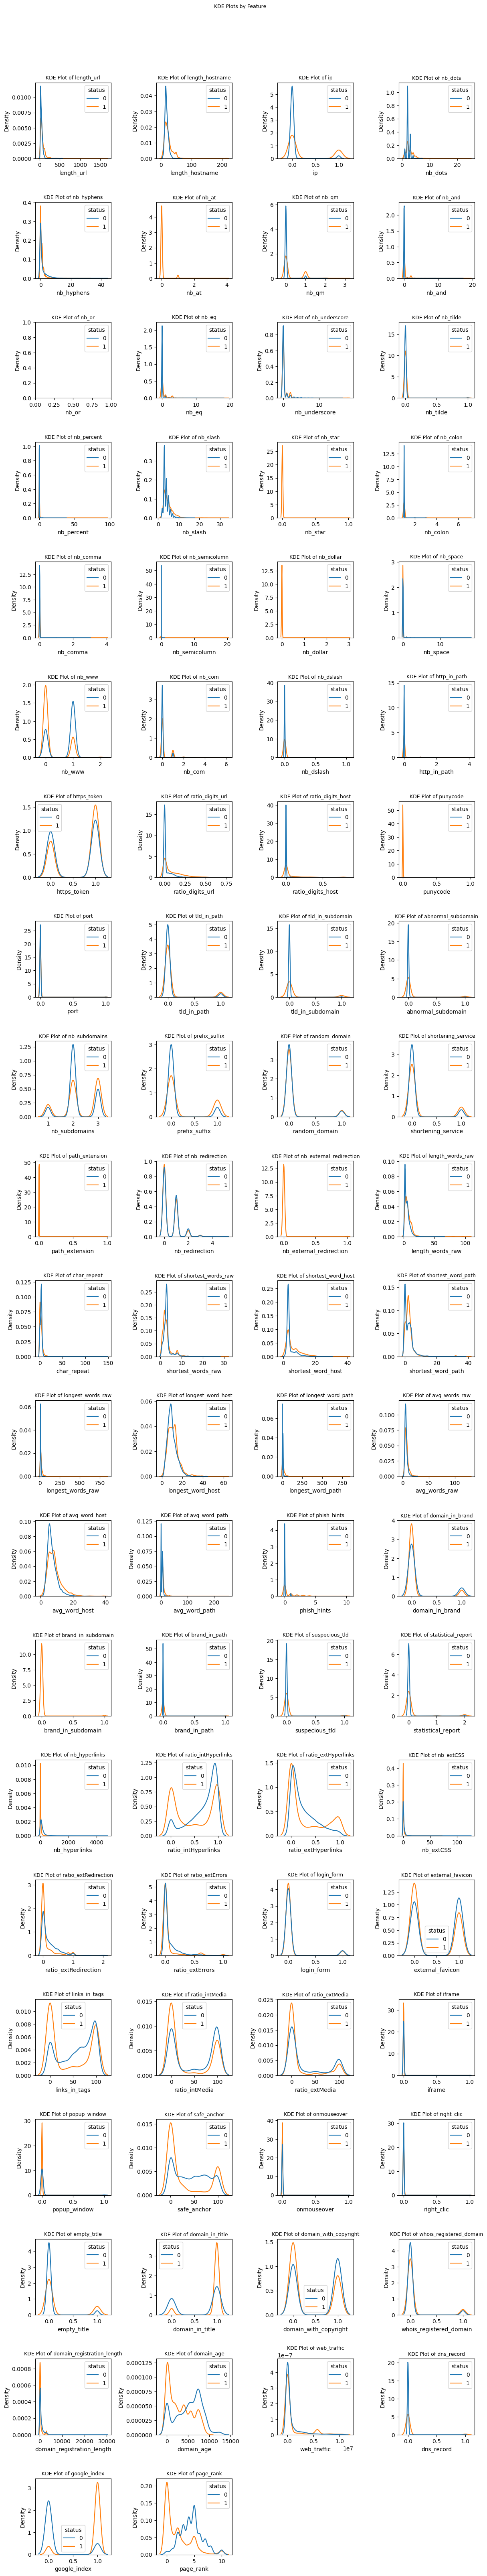

In [29]:
print("\nPerforming KDE Analysis...")
perform_kde_analysis(df_phishing_web_cleaned, n_cols=4, plot_size=3)

### KDE plot related Observation:

**Google indexing:** Websites in status group 0 tend to have a Google-index value of 0, while websites in status group 1 tend to have a value of 1. This difference suggests that Google-index information could help distinguish the two groups. We need to confirm what these values represent before interpreting them as indexed or not indexed.

**Page rank:** Websites in status group 1 tend to have low page ranks, often close to zero. Websites in status group 0 tend to have higher page ranks, commonly around 3 to 6. This suggests that page rank could help predict a website’s status.

**Domain age:** Websites in status group 1 tend to have domain-age values close to zero, while websites in status group 0 tend to have higher values. This may indicate that group 1 contains younger websites, provided that zero represents a real age rather than missing information.


### Module799- o1  Week 1


### Analysis based on VIF featurees

I selected these features to investigate possible multicollinearity, because our correlation table showed groups of predictors carrying related information(high correlation factor/score).
- URL and word-length features: length_url, length_words_raw, longest_words_raw, longest_word_path, avg_words_raw, and avg_word_path. Several were strongly correlated—for example, the longest raw/path word lengths had r ≈ 0.97, and URL length versus length_words_raw had r ≈ 0.79.
- Hostname and hostname-word features: length_hostname, longest_word_host, avg_word_host, and shortest_word_host. These measure related hostname characteristics. Longest versus average hostname-word length had r ≈ 0.82, while shortest versus average had r ≈ 0.80.
- URL punctuation counts: nb_and and nb_eq had r ≈ 0.90, suggesting considerable overlap in the information they provide.
- Link-related features: ratio_intHyperlinks, ratio_extHyperlinks, and links_in_tags. Internal-link ratio versus links in tags had r ≈ 0.80, while internal versus external-link ratios had r ≈ −0.57.
These correlations motivated the VIF check; they do not establish the VIF results. VIF examines how well each predictor can be explained by the others together.
This is a diagnostic feature set, not your final classification feature set. For your final model, calculate VIF again using the predictors actually included, including the interaction terms.

In [30]:
# Base and interaction features

DATA = df_phishing_web_cleaned.copy()
TARGET_COLUMN = "status"

# All numeric columns except the target
BASE_FEATURES = [
    column
    for column in DATA.select_dtypes(include="number").columns
    if column != TARGET_COLUMN
]

# Create selected interaction features
DATA["page_rank_x_google_index"] = (
    DATA["page_rank"] * DATA["google_index"]
)

DATA["ratio_intHyperlinks_x_safe_anchor"] = (
    DATA["ratio_intHyperlinks"] * DATA["safe_anchor"]
)

INTERACTION_FEATURES = [
    "page_rank_x_google_index",
    "ratio_intHyperlinks_x_safe_anchor"
]

# Baseline and expanded feature sets
BASE_MODEL_FEATURES = BASE_FEATURES

INTERACTION_MODEL_FEATURES = (
    BASE_FEATURES + INTERACTION_FEATURES
)

# Modeling data
X_base = DATA[BASE_MODEL_FEATURES]
X_interactions = DATA[INTERACTION_MODEL_FEATURES]
y = DATA[TARGET_COLUMN]

# Display results
print("Target: status")
print("0 = Not phishing, 1 = Phishing")
print(f"\nNumber of base features: {len(BASE_MODEL_FEATURES)}")
print(f"Number of interaction features: {len(INTERACTION_FEATURES)}")
print(f"X_base shape: {X_base.shape}")
print(f"X_interactions shape: {X_interactions.shape}")

print("\nInteraction features:")
print(INTERACTION_FEATURES)

# Bivariate analysis
#perform_bivariate_analysis(
#    df_phishing_web_cleaned,
#    n_cols=4,
#    plot_size=3
#)

Target: status
0 = Not phishing, 1 = Phishing

Number of base features: 82
Number of interaction features: 2
X_base shape: (10000, 82)
X_interactions shape: (10000, 84)

Interaction features:
['page_rank_x_google_index', 'ratio_intHyperlinks_x_safe_anchor']


### New

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, mean_squared_error, r2_score,
)


def compare_feature_removal(
    X_train, X_valid, y_train, y_valid,
    features_to_remove, vif_function
):
    """Compare original and reduced models using the same validation split."""

    # Including all features i want removed in features_to_remove.
    X_valid = X_valid.loc[:, X_train.columns]
    X_reduced_train = X_train.drop(columns=features_to_remove)
    X_reduced_valid = X_valid.drop(columns=features_to_remove)
    removed_label = ", ".join(features_to_remove) or "None"

    # Calculate VIF using training data only.
    vif = vif_function(X_reduced_train, "reduced base features")

    print(f"Removed: {removed_label}")
    print(f"Features: {X_train.shape[1]} -> {X_reduced_train.shape[1]}")
    print("\nVIF AFTER REMOVAL")
    display(vif)

    rows, models = [], {}
    model_inputs = [
        ("Original base model", X_train, X_valid, "None"),
        ("Reduced base model",
         X_reduced_train, X_reduced_valid, removed_label),
    ]

    # Refit both models to calculate their metrics consistently.
    for name, train, valid, removed in model_inputs:
        model = LinearRegression().fit(train, y_train)
        scores = model.predict(valid)
        predictions = (scores >= 0.5).astype(int)
        models[name] = model

        rows.append({
            "model": name,
            "removed_features": removed,
            "n_features": train.shape[1],
            "r2": r2_score(y_valid, scores),
            "rmse": mean_squared_error(y_valid, scores) ** 0.5,
            "accuracy": accuracy_score(y_valid, predictions),
            "precision": precision_score(
                y_valid, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid, predictions, zero_division=0
            ),
            "f1_score": f1_score(
                y_valid, predictions, zero_division=0
            ),
            # Use raw scores for AUC, without clipping.
            "roc_auc": roc_auc_score(y_valid, scores),
        })

    comparison = pd.DataFrame(rows)

    metrics = [
        "r2", "rmse", "accuracy",
        "precision", "recall", "f1_score", "roc_auc"
    ]

    changes = pd.DataFrame({
        "metric": metrics,
        "change_after_removal": [
            rows[1][metric] - rows[0][metric]
            for metric in metrics
        ],
    })

    print("\nORIGINAL VS REDUCED MODEL")
    display(comparison.round(6))

    print("\nVALIDATION-PERFORMANCE CHANGE")
    display(changes.round(8))

    print(
        "Lower RMSE is better; higher values are better for other metrics.\n"
        "Compare performance across validation folds before finalizing removals."
    )

    return {
        "retained_features": X_reduced_train.columns.tolist(),
        "removed_features": list(features_to_remove),
        "vif": vif,
        "comparison": comparison,
        "performance_change": changes,
        "model": models["Reduced base model"],
    }


# Call the method: remove BOTH features.
# Define the base features and target from the sampled dataset.
#X_base = sampled_df.drop(columns=["status"])
#y = sampled_df["status"]


X_base = DATA.drop(columns=["status"])
y = DATA["status"]

# Create the train/validation split used by the comparison.
X_base_train, X_base_test, y_train, y_test = train_test_split(
    X_base,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

def calculate_vif(X, label="features"):
    """Calculate variance inflation factors for numeric features."""

    X_numeric = X.select_dtypes(include="number").copy()
    X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan).dropna()

    vif_rows = []

    for index, column in enumerate(X_numeric.columns):
        if X_numeric[column].nunique() <= 1:
            vif_value = np.inf
        else:
            try:
                vif_value = variance_inflation_factor(
                    X_numeric.to_numpy(),
                    index,
                )
            except (ValueError, np.linalg.LinAlgError):
                vif_value = np.inf

        vif_rows.append({
            "feature": column,
            "VIF": vif_value,
        })

    return (
        pd.DataFrame(vif_rows)
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )


In [32]:
# Identify constant or entirely missing columns using training data only.
unique_counts = X_base_train.nunique(dropna=True)
constant_columns = unique_counts[unique_counts <= 1].index.tolist()

print("Constant or entirely missing columns:", constant_columns)

# Apply the same exclusions to both datasets.
X_train_clean = X_base_train.drop(columns=constant_columns)
X_valid_clean = X_base_test.loc[:, X_train_clean.columns]

print("Features after cleaning:", X_train_clean.shape[1])



Constant or entirely missing columns: ['nb_or']
Features after cleaning: 83


In [33]:
from sklearn.linear_model import LinearRegression

feature_removal = compare_feature_removal(
    X_train=X_train_clean,
    X_valid=X_valid_clean,
    y_train=y_train,
    y_valid=y_test,
    features_to_remove=[
        "avg_word_host",
        "longest_words_raw",
        "length_words_raw",
        "avg_words_raw",
        "nb_subdomains",
        "nb_colon",
        "nb_dots",
        "length_url",
        "ratio_intHyperlinks",
        "nb_eq",
        "length_hostname",
    ],
    vif_function=calculate_vif,
)

Removed: avg_word_host, longest_words_raw, length_words_raw, avg_words_raw, nb_subdomains, nb_colon, nb_dots, length_url, ratio_intHyperlinks, nb_eq, length_hostname
Features: 83 -> 72

VIF AFTER REMOVAL


,feature,VIF
0,ratio_intHyperlinks_x_safe_anchor,30.833035
1,safe_anchor,29.942366
2,nb_slash,11.161442
3,page_rank,10.620335
4,google_index,9.135872
...,...,...
67,nb_comma,1.026853
68,iframe,1.017961
69,right_clic,1.011090
70,punycode,1.007573



ORIGINAL VS REDUCED MODEL


,model,removed_features,n_features,r2,rmse,accuracy,precision,recall,f1_score,roc_auc
0,Original base model,None,83,0.734715,0.257529,0.933,0.941837,0.923,0.932323,0.978959
1,Reduced base model,"avg_word_host, longest_words_raw, length_words...",72,0.734324,0.257719,0.929,0.933333,0.924,0.928643,0.978865



VALIDATION-PERFORMANCE CHANGE


,metric,change_after_removal
0,r2,-0.000391
1,rmse,0.000190
2,accuracy,-0.004000
3,precision,-0.008503
4,recall,0.001000
5,f1_score,-0.003680
6,roc_auc,-0.000094


Lower RMSE is better; higher values are better for other metrics.
Compare performance across validation folds before finalizing removals.


## Here i added Interaction terms, removed multicolinear features using VIF

Prediction quality is similar: accuracy is unchanged, with slightly higher precision but slightly lower phishing recall. The number of columns which were we started at 87 is now reduced to 72 thereby it will help in computation 

#### Interaction Terms

page_rank_google_index: Both features showed differences between phishing and legitimate cases. We select their interaction to test whether the relationship between page rank and phishing changes depending on the Google-index code.

ratio_intHyperlinks_safe_anchor: Both features describe website-link characteristics and showed differences between the classes. We select their interaction to test whether the relationship between internal-link proportion and phishing changes with the safe-anchor measure.

#### Observation from the identified interaction terms:

Both interaction terms were statistically significant as their p-values are below the threshold of 0.05, suggesting that:
- The relationship between page rank and phishing changes with the Google-index value.
- The relationship between internal-link proportion and phishing changes with the safe-anchor value.
These findings support considering the features together.

page_rank_google_index: The coefficient is −0.0845, with p = 0.009. Higher page rank has a stronger negative association with phishing when google_index = 1 than when it is 0. This supports allowing the page-rank relationship to differ between the two index groups.

ratio_intHyperlinks_safe_anchor: The coefficient is +0.0182, with p < 0.001. As the safe-anchor value increases, the internal-link-ratio relationship with phishing becomes less negative and potentially positive. This supports considering the two features together.

Overall: Both interaction coefficients have 95% confidence intervals that exclude zero, providing statistical support within this fitted model. Cross-validation is still needed to determine whether including them improves predictions on new data.

### Reducing overfitting using 5 fold CV


In [34]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LinearRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

rmse = -cross_val_score(
    LinearRegression(),
    X_train_clean,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

print("RMSE per fold:", rmse.round(4))
print("Average RMSE:", round(rmse.mean(), 4))
print("Standard deviation:", round(rmse.std(), 4))

RMSE per fold: [0.2585 0.2615 0.2643 0.2626 0.2603]
Average RMSE: 0.2614
Standard deviation: 0.002


In [35]:
import pandas as pd

performance_comparison = pd.DataFrame({
    "Evaluation": ["Previous validation split", "5-fold cross-validation"],
    "RMSE": [
        feature_removal["comparison"].iloc[0]["rmse"],
        rmse.mean(),
    ],
    "RMSE_standard_deviation": [None, rmse.std()],
})

display(performance_comparison.round(4))

,Evaluation,RMSE,RMSE_standard_deviation
0,Previous validation split,0.2575,NaN
1,5-fold cross-validation,0.2614,0.002


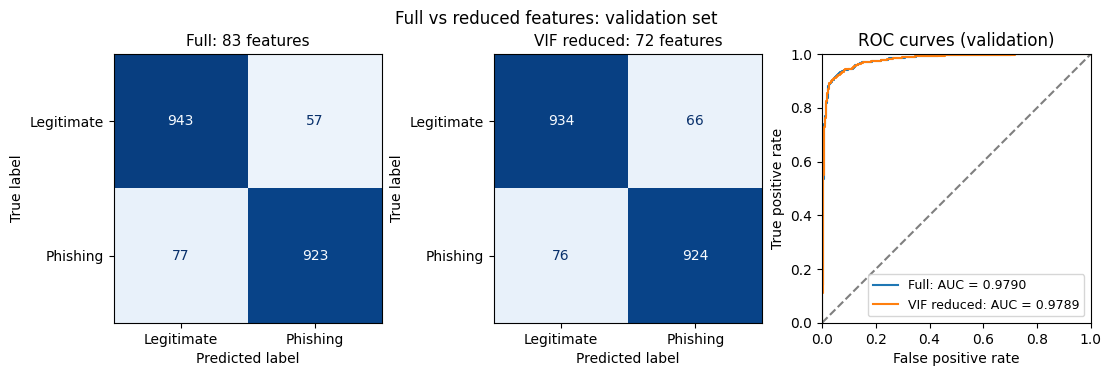

Rows evaluated per model: 2,000


In [36]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

feature_sets = {
    "Full": X_train_clean.columns.tolist(),
    "VIF reduced": feature_removal["retained_features"],
}

fig, axes = plt.subplots(
    1, 3, figsize=(11, 3.6), constrained_layout=True
)
fig.suptitle("Full vs reduced features: validation set")

max_count = max((y_test == 0).sum(), (y_test == 1).sum())
validation_scores = {}

for idx, (name, columns) in enumerate(feature_sets.items()):
    # Fit on training rows; predict the separate validation rows.
    model = LinearRegression().fit(
        X_train_clean[columns], y_train
    )
    scores = model.predict(X_valid_clean[columns])

    validation_scores[name] = scores
    predictions = (scores >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        labels=[0, 1],
        display_labels=["Legitimate", "Phishing"],
        cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": max_count},
        ax=axes[idx],
    )
    axes[idx].set_title(
        f"{name}: {len(columns)} features", fontsize=11
    )

    fpr, tpr, _ = roc_curve(y_test, scores, pos_label=1)
    auc = roc_auc_score(y_test, scores)
    axes[2].plot(fpr, tpr, label=f"{name}: AUC = {auc:.4f}")

axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].set(
    title="ROC curves (validation)",
    xlabel="False positive rate",
    ylabel="True positive rate",
    xlim=(0, 1), ylim=(0, 1),
)
axes[2].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.set_box_aspect(1)

plt.show()
print(f"Rows evaluated per model: {len(y_test):,}")

### So though we reduced so many features the model has not gone down on accuracy and AUC is nearly same as before with a very small degradation



### What did I learn in week 1:

How I can understand multicollineraity in features in a mathematical way and in datasets having large number if features how one can use VIF to reduce multicollinearity. It helps making the perfromance of the model more stable.  How I can improve perfromance of the regression model introduciong interaction terms. How I can use polinmial.

**Interaction terms** model how the effect of one feature changes depending on another feature. For example, page_rank × google_index allows the relationship between page rank and phishing to differ by Google-index status.
**VIF (Variance Inflation Factor)** measures how much a regression coefficient’s variance is inflated because its feature overlaps linearly with other predictors. High VIF indicates multicollinearity, which makes individual coefficients harder to estimate reliably.

From my this regression model I learnt :

- Adding interaction terms introduced a trade-off: accuracy improved from 92.9% to 93.3%, but phishing recall decreased from 93.5% to 92.3%.
- Removing 11 columns changed performance only slightly, suggesting substantial overlapping information, but lower VIF did not guarantee better predictions(as in the last part the rmse went up in a very small way).
- Feature selection needs both redundancy checks and predictive validation: I can use VIF to investigate overlap/multicollinearity, used cross-validation to make sure there is reduced overfitting (though in our dataset since we had good amount of data didnot see major change in performance due to CV), but if the rows would have been lesser I am sure we would have seen CV help reduce overfitting.
- In my application it was classification so it was binary and I did not use polynmial terms to reduce underfitting  but in ututure I will use it and in the classsroom week1 notebook I did experiment with it. 


## OMDS-799-o2 Week3 
I will use only dataset 2 this week as its moderate sized and has lot of columns which will be ideal for this week. Last week I used all three datasets that I had so this week will use one of those three

#### In this week i will use the same dataset as in week 1 (Phishing Website dataset) and apply :
- forward and backward selection
- PCA and PCR

In [37]:
from sklearn.decomposition import PCA

# Use the interaction names already present in your notebook.
INTERACTION_PARENTS = {
    "page_rank_x_google_index": ("page_rank", "google_index"),
    "ratio_intHyperlinks_x_safe_anchor": ("ratio_intHyperlinks", "safe_anchor"),
}

In [38]:
def _select_features(X, y, n_features, direction, n_splits):
    """Shared greedy search, using training-fold RMSE only."""
    if not 1 <= n_features <= X.shape[1]:
        raise ValueError("n_features must be between 1 and the input column count.")
    parents = {term: pair for term, pair in INTERACTION_PARENTS.items() if term in X}
    for term, pair in parents.items():
        if not set(pair).issubset(X.columns):
            raise ValueError(f"Include both parents of {term}: {pair}")

    folds = list(StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=42
    ).split(X, y))
    selected = [] if direction == "forward" else X.columns.tolist()
    history = []

    while len(selected) != n_features:
        best_rmse, best_feature, best_columns = np.inf, None, None
        candidates = [c for c in X.columns if c not in selected] if direction == "forward" else selected
        for feature in candidates:
            if direction == "forward":
                # Add an interaction only after both main effects are present.
                if not set(parents.get(feature, ())).issubset(selected):
                    continue
                columns = selected + [feature]
            else:
                # Remove an interaction before removing either parent.
                if any(term in selected and feature in pair for term, pair in parents.items()):
                    continue
                columns = [c for c in selected if c != feature]

            rmse = -cross_val_score(
                LinearRegression(), X[columns], y, cv=folds,
                scoring="neg_root_mean_squared_error", error_score="raise",
            ).mean()
            if rmse < best_rmse:
                best_rmse, best_feature, best_columns = rmse, feature, columns

        selected = best_columns
        history.append({
            "step": len(history) + 1,
            "added" if direction == "forward" else "removed": best_feature,
            "features": len(selected), "selection_cv_rmse": best_rmse,
        })
        print(f"{direction}: {len(selected)} features | CV RMSE {best_rmse:.4f}")

    return selected, pd.DataFrame(history)



def forward_selection(X, y, n_features=20, n_splits=5):
    """Start empty; add the feature giving the lowest CV RMSE at each step."""
    return _select_features(X, y, n_features, "forward", n_splits)



def backward_selection(X, y, n_features=20, n_splits=5):
    """Start full; remove the feature giving the lowest CV RMSE at each step."""
    return _select_features(X, y, n_features, "backward", n_splits)

In [39]:
def perform_pca(X_train, n_components=0.95):
    """Fit scaled PCA on training data; show the retained feature variance."""
    transformer = make_pipeline(
        StandardScaler(), PCA(n_components=n_components, svd_solver="full")
    ).fit(X_train)
    pca = transformer.named_steps["pca"]
    variance = pd.DataFrame({
        "component": np.arange(1, pca.n_components_ + 1),
        "explained_variance": pca.explained_variance_ratio_,
        "cumulative_variance": pca.explained_variance_ratio_.cumsum(),
    })
    print(f"{X_train.shape[1]} input columns -> {pca.n_components_} components")
    display(variance.round(4))
    fig, ax = plt.subplots(figsize=(4, 4), constrained_layout=True)
    ax.plot(variance["component"], variance["cumulative_variance"], marker=".")
    ax.set(xlabel="Components retained", ylabel="Cumulative feature variance",
           title="PCA: training data", ylim=(0, 1.02))
    ax.set_box_aspect(1)
    plt.show()
    return transformer

In [40]:
def perform_pcr(X_train, y_train, n_components=0.95):
    """Principal component regression: scale -> PCA -> linear regression."""
    return make_pipeline(
        StandardScaler(), PCA(n_components=n_components, svd_solver="full"),
        LinearRegression(),
    ).fit(X_train, y_train)

In [41]:
def compare_performance(models, X_valid, y_valid, baseline="Full",
                        threshold=0.5, rmse_tolerance=0.005,
                        n_cols=3, plot_size=3.2):
    """Compare fitted (model, input_columns) pairs on the same validation rows."""
    if baseline not in models:
        raise KeyError(f"Baseline {baseline!r} is not in models.")
    rows, predictions, scores_by_model = [], {}, {}
    for name, (model, columns) in models.items():
        scores = np.asarray(model.predict(X_valid.loc[:, columns])).ravel()
        predictions[name] = (scores >= threshold).astype(int)
        scores_by_model[name] = scores
        pca = getattr(model, "named_steps", {}).get("pca")
        rows.append({
            "model": name, "input_columns": len(columns),
            "model_dimensions": pca.n_components_ if pca is not None else len(columns),
            "rmse": mean_squared_error(y_valid, scores) ** 0.5,
            "r2": r2_score(y_valid, scores),
            "accuracy": accuracy_score(y_valid, predictions[name]),
            "precision": precision_score(y_valid, predictions[name], zero_division=0),
            "recall": recall_score(y_valid, predictions[name], zero_division=0),
            "f1_score": f1_score(y_valid, predictions[name], zero_division=0),
            # OLS scores are not probabilities; do not clip them for AUC.
            "roc_auc": roc_auc_score(y_valid, scores),
        })

    comparison = pd.DataFrame(rows).set_index("model")
    comparison.insert(3, "rmse_change", comparison["rmse"] - comparison.loc[baseline, "rmse"])
    comparison["within_rmse_tolerance"] = comparison["rmse_change"] <= rmse_tolerance
    display(comparison.round(6))
    print(f"RMSE change is relative to {baseline}; lower is better.")
    print(f"Allowed RMSE increase: {rmse_tolerance}. Also check phishing recall.")

    n_cols = min(n_cols, len(models))
    n_rows = (len(models) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(n_cols * plot_size, n_rows * plot_size),
        squeeze=False, constrained_layout=True,
    )
    max_count = max(np.sum(np.asarray(y_valid) == 0), np.sum(np.asarray(y_valid) == 1))
    for ax, name in zip(axes.flat, models):
        ConfusionMatrixDisplay.from_predictions(
            y_valid, predictions[name], labels=[0, 1],
            display_labels=["Legitimate", "Phishing"], ax=ax,
            cmap="Blues", colorbar=False, values_format="d",
            im_kw={"vmin": 0, "vmax": max_count},
        )
        ax.set_title(name, fontsize=10)
        ax.set_box_aspect(1)
    for ax in list(axes.flat)[len(models):]:
        fig.delaxes(ax)
    fig.suptitle(f"Validation confusion matrices (threshold = {threshold})")
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
    for name, scores in scores_by_model.items():
        fpr, tpr, _ = roc_curve(y_valid, scores, pos_label=1)
        ax.plot(fpr, tpr, label=f"{name}: AUC {comparison.loc[name, 'roc_auc']:.4f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set(title="Validation ROC curves", xlabel="False positive rate",
           ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
    ax.set_box_aspect(1)
    ax.legend(loc="lower right", fontsize=8)
    plt.show()
    return comparison

Prepare the existing full and VIF-reduced baselines

,input_columns,model_dimensions,rmse,rmse_change,r2,accuracy,precision,recall,f1_score,roc_auc,within_rmse_tolerance
model,,,,,,,,,,,
Full,83,83,0.257529,0.00000,0.734715,0.933,0.941837,0.923,0.932323,0.978959,True
VIF reduced,72,72,0.257719,0.00019,0.734324,0.929,0.933333,0.924,0.928643,0.978865,True


RMSE change is relative to Full; lower is better.
Allowed RMSE increase: 0.005. Also check phishing recall.


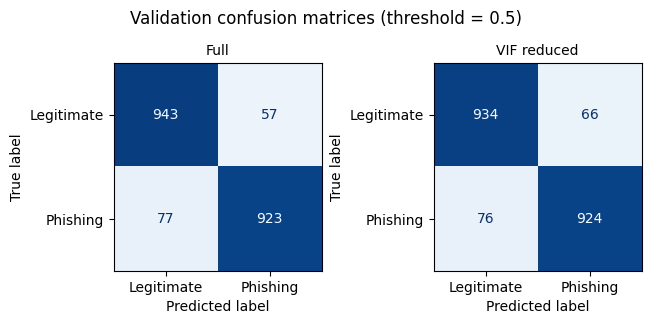

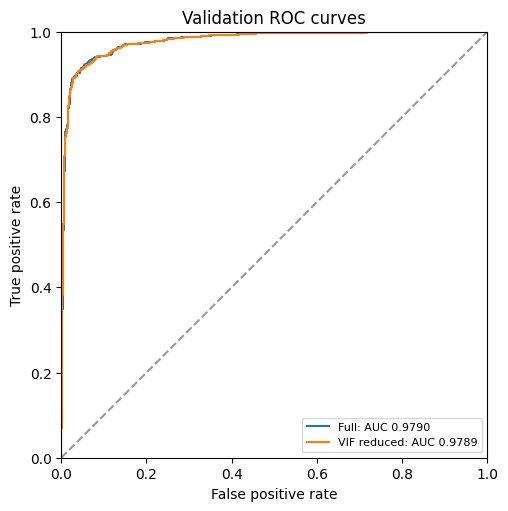

In [42]:
# Use the cleaned data and the SAME split already created above.
assert X_train_clean.index.equals(y_train.index), "Training rows and labels must align."
assert X_valid_clean.index.equals(y_test.index), "Validation rows and labels must align."
assert "status" not in X_train_clean.columns, "Do not include the target as a predictor."

full_features = X_train_clean.columns.tolist()
reduced_features = feature_removal["retained_features"]

models = {
    "Full": (
        LinearRegression().fit(X_train_clean, y_train), full_features
    ),
    "VIF reduced": (
        LinearRegression().fit(X_train_clean[reduced_features], y_train),
        reduced_features,
    ),
}

comparison = compare_performance(models, X_valid_clean, y_test)

Forward Selection

forward: 1 features | CV RMSE 0.3403
forward: 2 features | CV RMSE 0.3175
forward: 3 features | CV RMSE 0.3008
forward: 4 features | CV RMSE 0.2945
forward: 5 features | CV RMSE 0.2894
forward: 6 features | CV RMSE 0.2857
forward: 7 features | CV RMSE 0.2826
forward: 8 features | CV RMSE 0.2804
forward: 9 features | CV RMSE 0.2785
forward: 10 features | CV RMSE 0.2770
forward: 11 features | CV RMSE 0.2756
forward: 12 features | CV RMSE 0.2744
forward: 13 features | CV RMSE 0.2730
forward: 14 features | CV RMSE 0.2716
forward: 15 features | CV RMSE 0.2704
forward: 16 features | CV RMSE 0.2694
forward: 17 features | CV RMSE 0.2685
forward: 18 features | CV RMSE 0.2678
forward: 19 features | CV RMSE 0.2671
forward: 20 features | CV RMSE 0.2665
Forward-selected features: ['google_index', 'page_rank', 'nb_www', 'nb_qm', 'nb_hyperlinks', 'phish_hints', 'ratio_intHyperlinks', 'nb_hyphens', 'ratio_digits_url', 'shortening_service', 'ratio_extMedia', 'ratio_extHyperlinks', 'ratio_extRedirection

,step,added,features,selection_cv_rmse
0,1,google_index,1,0.34033
1,2,page_rank,2,0.31752
2,3,nb_www,3,0.30084
3,4,nb_qm,4,0.29450
4,5,nb_hyperlinks,5,0.28936
5,6,phish_hints,6,0.28566
6,7,ratio_intHyperlinks,7,0.28256
7,8,nb_hyphens,8,0.28037
8,9,ratio_digits_url,9,0.27853
9,10,shortening_service,10,0.27704


,input_columns,model_dimensions,rmse,rmse_change,r2,accuracy,precision,recall,f1_score,roc_auc,within_rmse_tolerance
model,,,,,,,,,,,
Full,83,83,0.257529,0.000000,0.734715,0.933,0.941837,0.923,0.932323,0.978959,True
VIF reduced,72,72,0.257719,0.000190,0.734324,0.929,0.933333,0.924,0.928643,0.978865,True
Forward 31,20,20,0.265328,0.007799,0.718404,0.924,0.930020,0.917,0.923464,0.974383,False


RMSE change is relative to Full; lower is better.
Allowed RMSE increase: 0.005. Also check phishing recall.


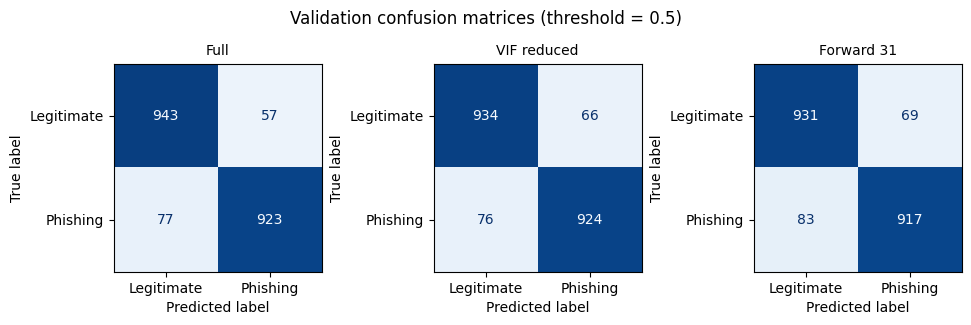

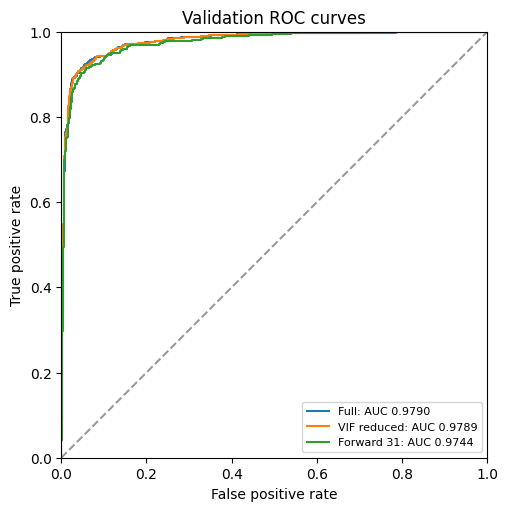

In [43]:
forward_features, forward_history = forward_selection(
    X_train_clean, y_train, n_features=20, n_splits=5
)
print("Forward-selected features:", forward_features)
display(forward_history.round(5))

models["Forward 31"] = (
    LinearRegression().fit(X_train_clean[forward_features], y_train),
    forward_features,
)
comparison = compare_performance(models, X_valid_clean, y_test)

Backward Selection and keep 62 as it will take a lot of time so we will remove 20

backward: 82 features | CV RMSE 0.2613
backward: 81 features | CV RMSE 0.2612
backward: 80 features | CV RMSE 0.2611
backward: 79 features | CV RMSE 0.2610
backward: 78 features | CV RMSE 0.2610
backward: 77 features | CV RMSE 0.2609
backward: 76 features | CV RMSE 0.2608
backward: 75 features | CV RMSE 0.2608
backward: 74 features | CV RMSE 0.2608
backward: 73 features | CV RMSE 0.2607
backward: 72 features | CV RMSE 0.2607
backward: 71 features | CV RMSE 0.2607
backward: 70 features | CV RMSE 0.2606
backward: 69 features | CV RMSE 0.2606
backward: 68 features | CV RMSE 0.2606
backward: 67 features | CV RMSE 0.2606
backward: 66 features | CV RMSE 0.2606
backward: 65 features | CV RMSE 0.2606
backward: 64 features | CV RMSE 0.2606
backward: 63 features | CV RMSE 0.2605
backward: 62 features | CV RMSE 0.2605
backward: 61 features | CV RMSE 0.2605
Backward-selected features: ['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_undersco

,step,removed,features,selection_cv_rmse
0,1,char_repeat,82,0.26129
1,2,shortest_word_host,81,0.26119
2,3,shortest_words_raw,80,0.26110
3,4,brand_in_path,79,0.26103
4,5,http_in_path,78,0.26095
5,6,nb_dollar,77,0.26090
6,7,random_domain,76,0.26084
7,8,login_form,75,0.26080
8,9,right_clic,74,0.26076
9,10,tld_in_path,73,0.26072


,input_columns,model_dimensions,rmse,rmse_change,r2,accuracy,precision,recall,f1_score,roc_auc,within_rmse_tolerance
model,,,,,,,,,,,
Full,83,83,0.257529,0.000000,0.734715,0.933,0.941837,0.923,0.932323,0.978959,True
VIF reduced,72,72,0.257719,0.000190,0.734324,0.929,0.933333,0.924,0.928643,0.978865,True
Forward 31,20,20,0.265328,0.007799,0.718404,0.924,0.930020,0.917,0.923464,0.974383,False
Backward 20,61,61,0.257732,0.000203,0.734297,0.933,0.940041,0.925,0.932460,0.978809,True


RMSE change is relative to Full; lower is better.
Allowed RMSE increase: 0.005. Also check phishing recall.


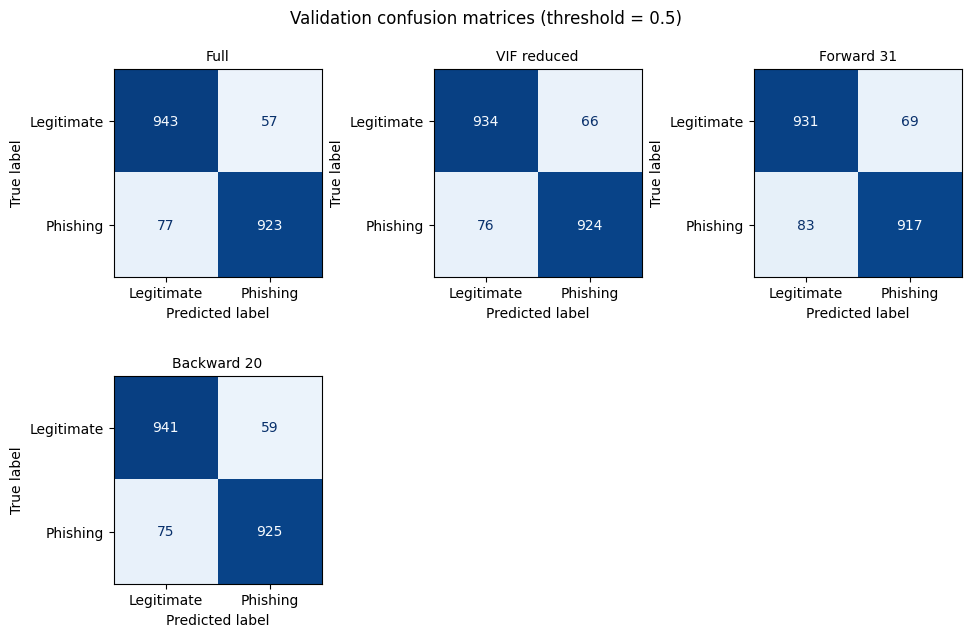

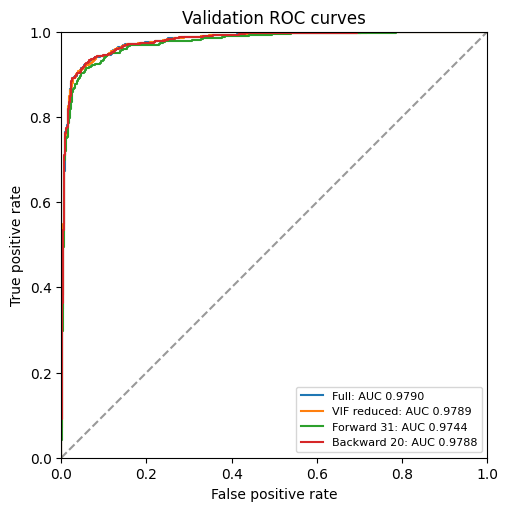

In [44]:
backward_features, backward_history = backward_selection(
    X_train_clean, y_train, n_features=61, n_splits=5
)
print("Backward-selected features:", backward_features)
display(backward_history.round(5))

models["Backward 20"] = (
    LinearRegression().fit(X_train_clean[backward_features], y_train),
    backward_features,
)
comparison = compare_performance(models, X_valid_clean, y_test)

PCA


83 input columns -> 60 components


,component,explained_variance,cumulative_variance
0,1,0.1006,0.1006
1,2,0.0564,0.1570
2,3,0.0512,0.2082
3,4,0.0445,0.2528
4,5,0.0355,0.2882
5,6,0.0328,0.3211
6,7,0.0293,0.3503
7,8,0.0247,0.3751
8,9,0.0238,0.3989
9,10,0.0216,0.4205


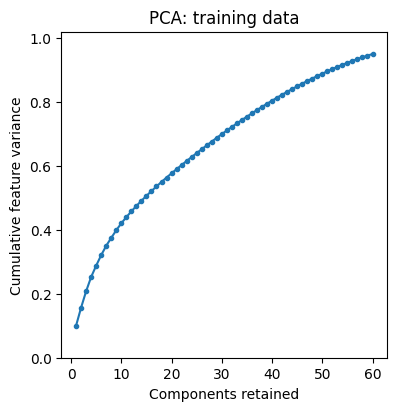

PCA training shape: (8000, 60)
PCA validation shape: (2000, 60)


In [45]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pca_transformer = perform_pca(X_train_clean, n_components=0.95)

# Use the SAME fitted transformation on training and validation rows.
X_train_pca = pca_transformer.transform(X_train_clean)
X_valid_pca = pca_transformer.transform(X_valid_clean[full_features])
print("PCA training shape:", X_train_pca.shape)
print("PCA validation shape:", X_valid_pca.shape)

PCR

,input_columns,model_dimensions,rmse,rmse_change,r2,accuracy,precision,recall,f1_score,roc_auc,within_rmse_tolerance
model,,,,,,,,,,,
Full,83,83,0.257529,0.000000,0.734715,0.9330,0.941837,0.923,0.932323,0.978959,True
VIF reduced,72,72,0.257719,0.000190,0.734324,0.9290,0.933333,0.924,0.928643,0.978865,True
Forward 31,20,20,0.265328,0.007799,0.718404,0.9240,0.930020,0.917,0.923464,0.974383,False
Backward 20,61,61,0.257732,0.000203,0.734297,0.9330,0.940041,0.925,0.932460,0.978809,True
PCR 95% variance,83,60,0.270811,0.013282,0.706645,0.9305,0.928358,0.933,0.930673,0.976114,False


RMSE change is relative to Full; lower is better.
Allowed RMSE increase: 0.005. Also check phishing recall.


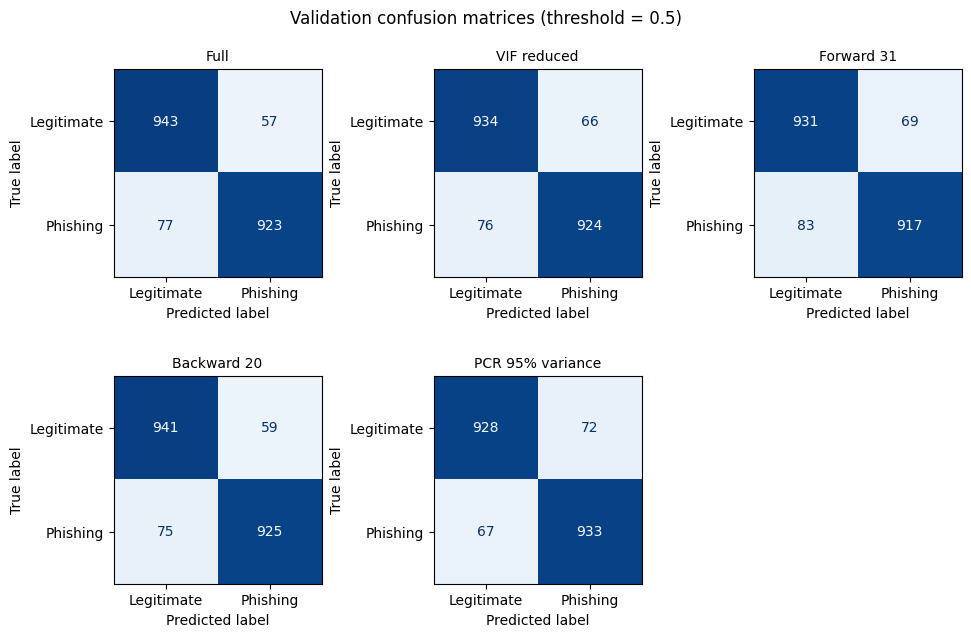

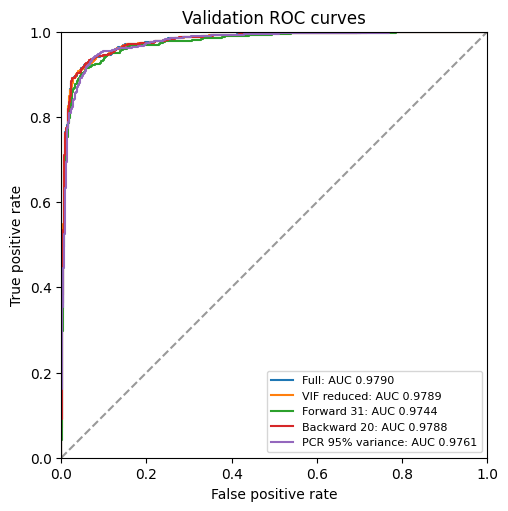

In [46]:
components_95 = pca_transformer.named_steps["pca"].n_components_
models["PCR 95% variance"] = (
    perform_pcr(X_train_clean, y_train, n_components=components_95),
    full_features,
)
comparison = compare_performance(models, X_valid_clean, y_test)